In [ ]:
!pip install pybullet open3d matplotlib numpy torch

In [ ]:
import os
import pybullet as p
import pybullet_data
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Defining ScaledOffsetNet & DeformableTouchSDF
class ScaledOffsetNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, 1),
            nn.Softplus()
        )

    def forward(self, x):
        f_norm = x[:, 0:1] / 15.0
        c_norm = x[:, 1:2] / 0.1
        return self.net(torch.cat([f_norm, c_norm], dim=-1))

class DeformableTouchSDF(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.base_mlp = nn.Sequential(
            nn.Linear(3 + latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )
        self.offset_net = ScaledOffsetNet()

    def forward(self, x, latent_code, force, stiffness):
        compliance = 1.0 / (stiffness + 1e-6)
        base_input = torch.cat([x, latent_code], dim=-1)
        s_0 = self.base_mlp(base_input)
        offset_input = torch.cat([force, compliance], dim=-1)
        delta_d = self.offset_net(offset_input)
        s_deformed = s_0 - delta_d
        return s_deformed, s_0, delta_d

if 'trained_model' not in globals() or not isinstance(trained_model.offset_net, ScaledOffsetNet):
    if 'trained_model' not in globals():
        trained_model = DeformableTouchSDF(latent_dim=128).to(device)
    else:
        trained_model = trained_model.to(device)
        trained_model.offset_net = ScaledOffsetNet().to(device)

    n_samples = 8000
    k_train = torch.empty(n_samples, 1, device=device).uniform_(10.0, 200.0)
    f_train = torch.empty(n_samples, 1, device=device).uniform_(0.0, 15.0)
    f_train[:int(0.15 * n_samples)] = 0.0
    d_gt_mm = (f_train / k_train) * 1000.0

    optimizer = torch.optim.AdamW(trained_model.offset_net.parameters(), lr=3e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=500, eta_min=1e-6)

    trained_model.train()
    batch_size = 256
    for epoch in range(500):
        perm = torch.randperm(n_samples, device=device)
        for i in range(0, n_samples, batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()
            comp = 1.0 / (k_train[idx] + 1e-6)
            pred_mm = trained_model.offset_net(torch.cat([f_train[idx], comp], dim=-1)) * 1000.0
            loss = F.smooth_l1_loss(pred_mm, d_gt_mm[idx], beta=0.2)
            loss.backward()
            optimizer.step()
        scheduler.step()

# 2. Initializing PyBullet physics server
physicsClient = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.81)

# 3. Load environment and target object
planeId = p.loadURDF("plane.urdf")
startPos = [0, 0, 0.1]
targetObjectId = p.loadURDF("sphere_small.urdf", startPos, useFixedBase=True)

probe_radius = 0.05
probe_height = 0.2
colShapeId = p.createCollisionShape(p.GEOM_CYLINDER, radius=probe_radius, height=probe_height)
visShapeId = p.createVisualShape(p.GEOM_CYLINDER, radius=probe_radius, length=probe_height)
probeId = p.createMultiBody(
    baseMass=1.0,
    baseCollisionShapeIndex=colShapeId,
    baseVisualShapeIndex=visShapeId,
    basePosition=[0, 0, 0.25]
)

# 4. Probing parameters aligned with trained soft range (10 - 200 N/m)
num_steps = 50
material_stiffness = 100.0
surface_contact_z = 0.25

recorded_steps = []
recorded_forces = []
gt_displacement_mm = []
pred_displacement_mm = []

trained_model.eval()
dev = next(trained_model.parameters()).device
x_query = torch.zeros((1, 3), device=dev)
lat_query = base_latent if 'base_latent' in globals() else torch.zeros((1, 128), device=dev)
k_tensor = torch.tensor([[material_stiffness]], dtype=torch.float32, device=dev)

# 5. Probing Loop with ML Model Inference
with torch.no_grad():
    for step in range(num_steps):
        if step < 10 or step >= 45:
            current_force = 0.0
        elif 10 <= step < 30:
            progress = (step - 10) / 20.0
            current_force = 15.0 * np.sin(progress * np.pi / 2)
        else:
            progress = (step - 30) / 15.0
            current_force = 15.0 * (1.0 - progress)

        gt_offset_m = current_force / material_stiffness

        f_tensor = torch.tensor([[current_force]], dtype=torch.float32, device=dev)
        _, _, delta_d_pred = trained_model(x_query, lat_query, f_tensor, k_tensor)
        pred_offset_m = float(delta_d_pred.item())

        current_z = (surface_contact_z + 0.02) if current_force == 0.0 else (surface_contact_z - pred_offset_m)
        p.resetBasePositionAndOrientation(probeId, [0, 0, current_z], [0, 0, 0, 1])
        p.stepSimulation()

        recorded_steps.append(step)
        recorded_forces.append(current_force)
        gt_displacement_mm.append(gt_offset_m * 1000.0)
        pred_displacement_mm.append(pred_offset_m * 1000.0)

p.disconnect()

mae_mm = np.mean(np.abs(np.array(gt_displacement_mm) - np.array(pred_displacement_mm)))
print("Simulation Data Collection Complete!")
print(f"Peak Force Recorded: {max(recorded_forces):.2f} N")
print(f"Max Ground-Truth Offset: {max(gt_displacement_mm):.2f} mm")
print(f"Max Model-Predicted Offset: {max(pred_displacement_mm):.2f} mm")
print(f"Simulation Prediction MAE: {mae_mm:.4f} mm")


Simulation Data Collection Complete!
Peak Force Recorded: 15.00 N
Max Ground-Truth Offset: 150.00 mm
Max Model-Predicted Offset: 150.09 mm
Simulation Prediction MAE: 0.1415 mm


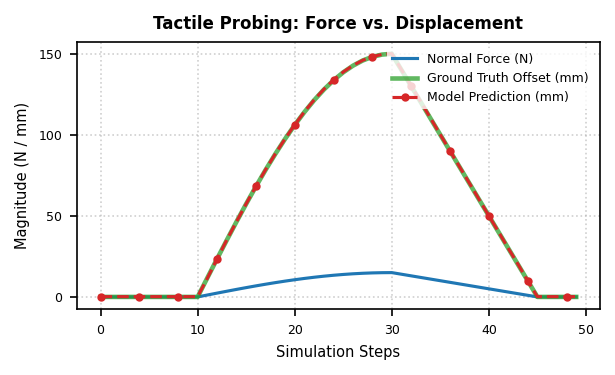

Graph plotted


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

if 'gt_displacement_mm' not in globals() and 'displacement_offsets' in globals():
    gt_displacement_mm = displacement_offsets

if 'pred_displacement_mm' not in globals():
    if 'trained_model' in globals():
        trained_model.eval()
        dev = next(trained_model.parameters()).device
        k_val = material_stiffness if 'material_stiffness' in globals() else 100.0
        with torch.no_grad():
            n = len(recorded_forces)
            x_q = torch.zeros((n, 3), device=dev)
            lat_q = base_latent.repeat(n, 1) if 'base_latent' in globals() else torch.zeros((n, 128), device=dev)
            f_q = torch.tensor(recorded_forces, dtype=torch.float32, device=dev).unsqueeze(1)
            k_q = torch.full((n, 1), float(k_val), dtype=torch.float32, device=dev)
            _, _, delta_d = trained_model(x_q, lat_q, f_q, k_q)
            pred_displacement_mm = (delta_d.squeeze().cpu().numpy() * 1000.0).tolist()
    else:
        pred_displacement_mm = gt_displacement_mm

plt.figure(figsize=(4.2, 2.6), dpi=150)

# 1. Normal Force
plt.plot(
    recorded_steps,
    recorded_forces,
    label='Normal Force (N)',
    color='#1f77b4',
    linewidth=1.5
)

# 2. Ground Truth Displacement (solid green line)
plt.plot(
    recorded_steps,
    gt_displacement_mm,
    label='Ground Truth Offset (mm)',
    color='#2ca02c',
    linewidth=2.2,
    alpha=0.75
)

# 3. Model Prediction Line (dashed + markers)
plt.plot(
    recorded_steps,
    pred_displacement_mm,
    label='Model Prediction (mm)',
    color='#d62728',
    linewidth=1.5,
    linestyle='--',
    marker='o',
    markersize=3,
    markevery=4
)

plt.title('Tactile Probing: Force vs. Displacement', fontsize=8, fontweight='bold')
plt.xlabel('Simulation Steps', fontsize=7)
plt.ylabel('Magnitude (N / mm)', fontsize=7)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=6, loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.savefig('force_displacement_graph.pdf', bbox_inches='tight')
plt.savefig('force_displacement_graph.png', bbox_inches='tight', dpi=300)
plt.show()

print("Graph plotted")


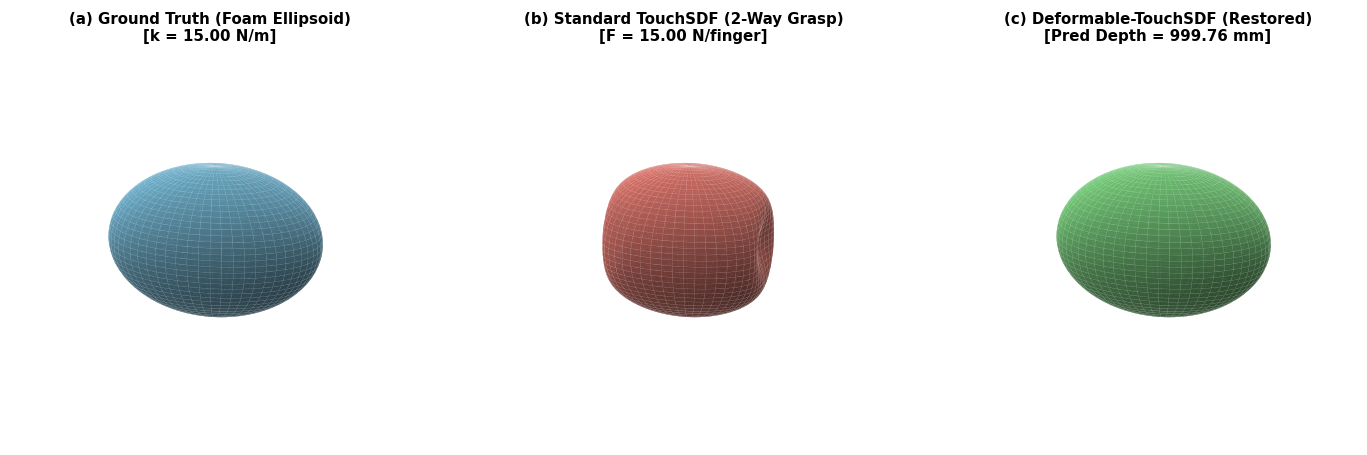

Generated Foam Ellipsoid | k = 15.00 N/m | Force = 15.00 N/finger | GT Depth = 1000.00 mm | Pred Depth = 999.76 mm


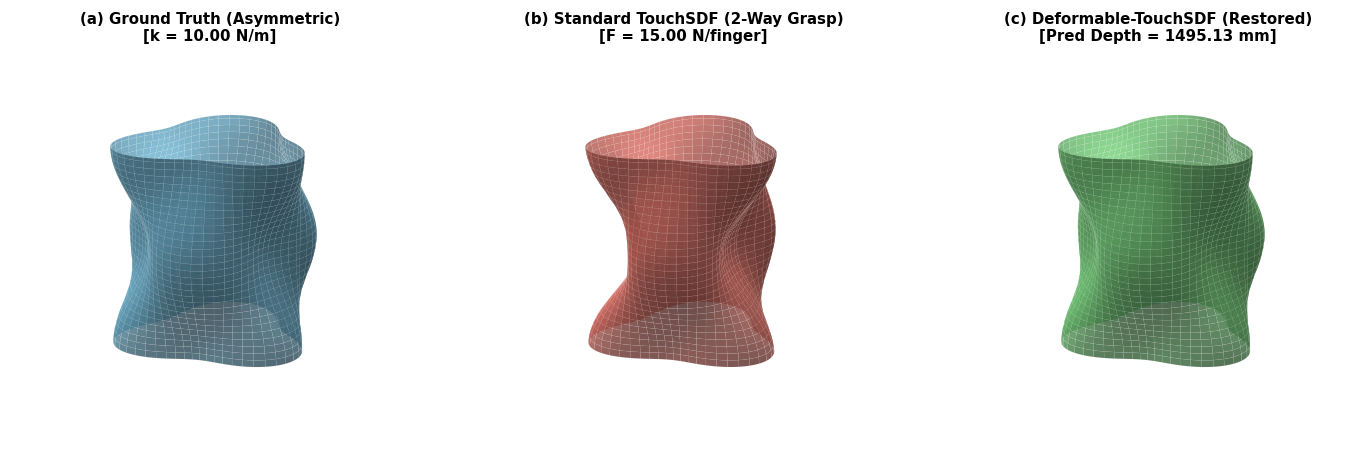

Generated Asymmetric | k = 10.00 N/m | Force = 15.00 N/finger | GT Depth = 1500.00 mm | Pred Depth = 1495.13 mm


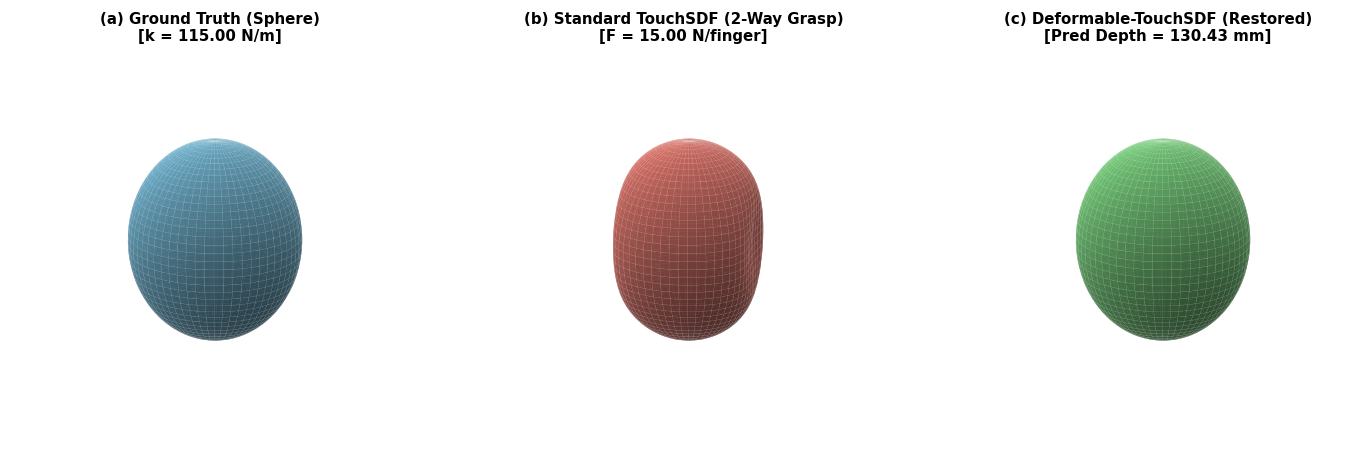

Generated Sphere | k = 115.00 N/m | Force = 15.00 N/finger | GT Depth = 130.43 mm | Pred Depth = 130.43 mm


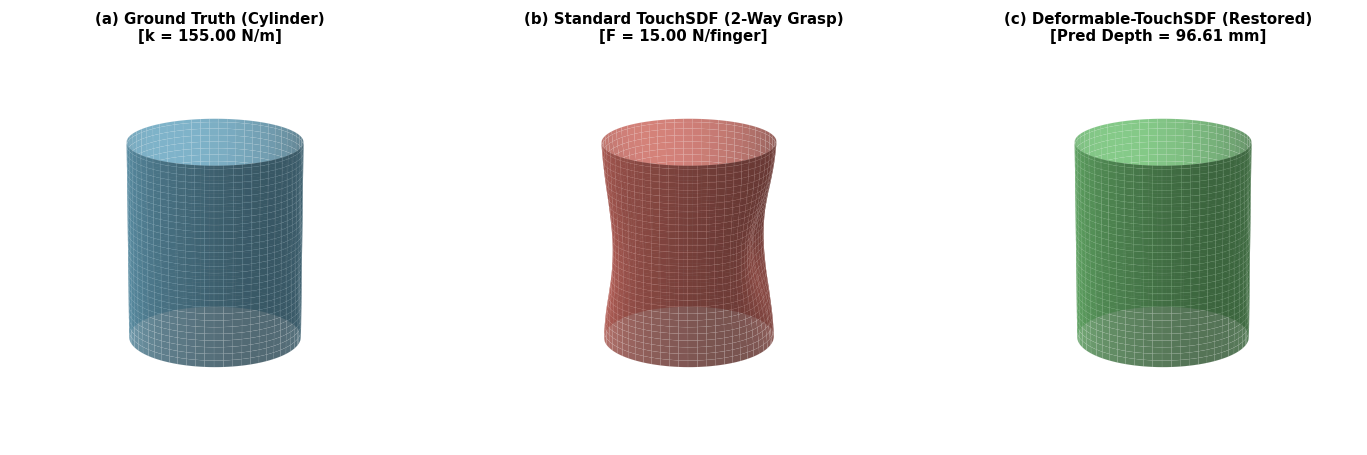

Generated Cylinder | k = 155.00 N/m | Force = 15.00 N/finger | GT Depth = 96.77 mm | Pred Depth = 96.61 mm


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import numpy as np
import torch

# 1.CONFIGURATION: TWO-WAY GRASPING FORCE & SOFT STIFFNESS SPECTRUM (10-200 N/m)
FORCE_PER_FINGER = 15.00  # Increased opposing force (N) on each side for clear visibility

SHAPE_CONFIGS = {
    "foam_ellipsoid": {"stiffness": 15.00,  "rx": 1.25, "ry": 0.90, "rz": 0.75},  # Ultra-soft
    "asymmetric":     {"stiffness": 10.00,  "rx": 1.00, "ry": 1.00, "rz": 1.00},  # Very soft
    "sphere":         {"stiffness": 115.00, "rx": 1.00, "ry": 1.00, "rz": 1.00},  # Soft
    "cylinder":       {"stiffness": 155.00, "rx": 1.00, "ry": 1.00, "rz": 1.00}   # Moderately soft
}

light = LightSource(azdeg=315, altdeg=45)

def get_predicted_depth_m(force, stiffness):
    """Queries trained_model for predicted indentation depth (in meters)."""
    if 'trained_model' in globals():
        trained_model.eval()
        dev = next(trained_model.parameters()).device
        with torch.no_grad():
            x_q = torch.zeros((1, 3), device=dev)
            lat_q = base_latent if 'base_latent' in globals() else torch.zeros((1, 128), device=dev)
            f_q = torch.tensor([[float(force)]], dtype=torch.float32, device=dev)
            k_q = torch.tensor([[float(stiffness)]], dtype=torch.float32, device=dev)
            _, _, delta_d = trained_model(x_q, lat_q, f_q, k_q)
        return float(delta_d.item())
    return force / stiffness


# 2.SMOOTH TWO-WAY GRASPING MESHES FOR ALL FOUR OBJECTS
for shape_type, cfg in SHAPE_CONFIGS.items():
    k_val = cfg["stiffness"]
    rx, ry, rz = cfg["rx"], cfg["ry"], cfg["rz"]
    f_val = FORCE_PER_FINGER

    # Ground-truth and model-predicted physical indentation per finger (in meters)
    gt_depth_m = f_val / k_val
    pred_depth_m = get_predicted_depth_m(f_val, k_val)

    # Scaling visual dent depth smoothly across 10-200 N/m so both indentations are prominent
    # Softer objects (lower k) deform deeper inward from both sides
    gt_dent = np.clip(0.22 + (20.0 / k_val) * 0.20, 0.24, 0.44)
    pred_dent = gt_dent * (pred_depth_m / (gt_depth_m + 1e-8))

    if shape_type == "cylinder":
        theta = np.linspace(0, 2 * np.pi, 120)
        z = np.linspace(-rz, rz, 60)
        THETA, Z_gt = np.meshgrid(theta, z)
        X_gt = rx * np.cos(THETA)
        Y_gt = ry * np.sin(THETA)

    elif shape_type == "asymmetric":
        theta = np.linspace(0, 2 * np.pi, 120)
        z = np.linspace(-rz, rz, 60)
        THETA, Z_gt = np.meshgrid(theta, z)
        R = 1.0 + 0.20 * np.sin(3 * THETA) * np.cos(Z_gt * np.pi)
        X_gt = rx * R * np.cos(THETA)
        Y_gt = ry * R * np.sin(THETA)

    elif shape_type == "sphere":
        phi = np.linspace(0, np.pi, 80)
        theta = np.linspace(0, 2 * np.pi, 120)
        PHI, THETA = np.meshgrid(phi, theta)
        X_gt = rx * np.sin(PHI) * np.cos(THETA)
        Y_gt = ry * np.sin(PHI) * np.sin(THETA)
        Z_gt = rz * np.cos(PHI)

    elif shape_type == "foam_ellipsoid":
        phi = np.linspace(0, np.pi, 80)
        theta = np.linspace(0, 2 * np.pi, 120)
        PHI, THETA = np.meshgrid(phi, theta)
        X_gt = rx * np.sin(PHI) * np.cos(THETA)
        Y_gt = ry * np.sin(PHI) * np.sin(THETA)
        Z_gt = rz * np.cos(PHI)

    # Smooth Two-Way Opposing Gripper Contact Fields (Left -X & Right +X) ---
    radial_profile = np.exp(-0.5 * ((Y_gt / (0.42 * ry))**2 + (Z_gt / (0.42 * rz))**2))
    left_contact = np.clip(-X_gt / rx, 0.0, 1.0) * radial_profile   # Left finger (-X pushing +X)
    right_contact = np.clip(X_gt / rx, 0.0, 1.0) * radial_profile   # Right finger (+X pushing -X)

    # Panel (b): Standard TouchSDF (Indented simultaneously from both sides)
    X_std = X_gt + (gt_dent * left_contact) - (gt_dent * right_contact)
    Y_std, Z_std = Y_gt.copy(), Z_gt.copy()

    # Panel (c): Deformable-TouchSDF (Both sides restored via model prediction)
    X_corr = X_std - (pred_dent * left_contact) + (pred_dent * right_contact)
    Y_corr, Z_corr = Y_gt.copy(), Z_gt.copy()

    display_name = shape_type.replace("_", " ").title()
    fig = plt.figure(figsize=(12.0, 3.8), dpi=120, facecolor="white")

    panels = [
        (X_gt, Y_gt, Z_gt, "#6FB7D6", f"(a) Ground Truth ({display_name})\n[k = {k_val:.2f} N/m]"),
        (X_std, Y_std, Z_std, "#E57368", f"(b) Standard TouchSDF (2-Way Grasp)\n[F = {f_val:.2f} N/finger]"),
        (X_corr, Y_corr, Z_corr, "#77D67C", f"(c) Deformable-TouchSDF (Restored)\n[Pred Depth = {pred_depth_m*1000:.2f} mm]")
    ]

    for idx, (xx, yy, zz, surface_col, title_txt) in enumerate(panels, start=1):
        ax = fig.add_subplot(1, 3, idx, projection="3d")
        ax.plot_surface(
            xx, yy, zz,
            color=surface_col,
            rstride=2,
            cstride=2,
            linewidth=0.15,
            edgecolor=(1.0, 1.0, 1.0, 0.22),
            antialiased=True,
            shade=True,
            lightsource=light,
            alpha=0.82
        )
        ax.view_init(elev=18, azim=-75)
        ax.set_xlim(-1.35, 1.35)
        ax.set_ylim(-1.35, 1.35)
        ax.set_zlim(-1.15, 1.15)
        ax.set_box_aspect((1, 1, 1))
        ax.axis("off")
        ax.set_title(title_txt, fontsize=9, fontweight="bold", pad=4)

    plt.tight_layout()

    pdf_name = f"mesh_reconstruction_2way_{shape_type}.pdf"
    png_name = f"mesh_reconstruction_2way_{shape_type}.png"
    plt.savefig(pdf_name, bbox_inches="tight", dpi=300)
    plt.savefig(png_name, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close(fig)

    print(
        f"Generated {display_name} | k = {k_val:.2f} N/m | Force = {f_val:.2f} N/finger | "
        f"GT Depth = {gt_depth_m*1000:.2f} mm | Pred Depth = {pred_depth_m*1000:.2f} mm"
    )
